# Modelos ML | Modelo #7 - XGBoost

Este notebook estima a superfície de volatilidade implícita (IVS) usando a técnica de Machine Learning XGBoost sobre os resíduos do modelo #3 - Splines.
Autor: Sérgio Sobral  
Data: 22/09/2025

Importação de Bibliotecas

In [1]:
import os
import json
import joblib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score
from typing import Optional, Sequence, Iterable, Tuple
from sklearn.base import BaseEstimator, TransformerMixin

from __future__ import annotations

from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

Designações Centrais e Caminhos

In [2]:
# Designações Centrais e Caminhos
DIR_TRATADOS = "02. Dados/02. Dados Tratados/"
DIR_RESULTADOS = "04. Resultados/07. Modelo #7 - Híbrido (XGBoost)/"
DIR_GRAFICOS = "03. Output/01. Gráficos/10. Modelo #7 - Híbrido (XGBoost)/"
DIR_TABELAS = "03. Output/02. Tabelas/07. Modelo #7 - Híbrido (XGBoost)/"
DIR_RESULTADOS_SPLINES = "04. Resultados/03. Modelo #3 - Splines/"

# Criar diretório de gráficos/tabelas/resultados se não existir
os.makedirs(DIR_GRAFICOS, exist_ok=True)
os.makedirs(DIR_RESULTADOS, exist_ok=True)
os.makedirs(DIR_TABELAS, exist_ok=True)

# Ficheiros de input
ficheiro_universo        = os.path.join(DIR_TRATADOS, "Universo_Modelizacao_v1.00.parquet")
ficheiro_inner_train     = os.path.join(DIR_TRATADOS, "df_inner_train.parquet")
ficheiro_inner_tunning   = os.path.join(DIR_TRATADOS, "df_inner_tunning.parquet")
ficheiro_train_full      = os.path.join(DIR_TRATADOS, "df_train_full.parquet")
ficheiro_test_puro       = os.path.join(DIR_TRATADOS, "df_test_puro.parquet")

# Caminhos do modelo Splines (para carregar previsões base)
SPLINES_MODEL_PATH_FINAL = os.path.join(DIR_RESULTADOS_SPLINES, "03. Splines_model.joblib")
SPLINES_META_PATH_FINAL  = os.path.join(DIR_RESULTADOS_SPLINES, "03. Splines_model.meta.json")

# Save Models (nomes finais)
MODEL_PATH_INNER = os.path.join(DIR_RESULTADOS, "07. Híbrido_XGBoost_model_inner.joblib")
META_PATH_INNER  = os.path.join(DIR_RESULTADOS, "07. Híbrido_XGBoost_model_inner.meta.json")

BEST_PARAMS = os.path.join(DIR_RESULTADOS, "07. Híbrido_XGBoost_best_params.json")
LINEAR_ADJUST = os.path.join(DIR_RESULTADOS, "07. Híbrido_XGBoost_linear_adjust.json")

MODEL_PATH_FINAL = os.path.join(DIR_RESULTADOS, "07. Híbrido_XGBoost_model.joblib")
META_PATH_FINAL  = os.path.join(DIR_RESULTADOS, "07. Híbrido_XGBoost_model.meta.json")

Funções Auxiliares

Palete de Cores:
azul1: #11469b
azul2: #2063c0
azul3: #5a90e7
cinza1: #777777
cinza2: #AAAAAA
cinza3: #bbbbbb
preto: #000000
branco: #ffffff

Estilos de Linha:
contínua: -
tracejada: --
ponto-traço: -.
pontilhada: :
contínua2: -
tracejada2: --
ponto-traço2: -.
pontilhada2: :


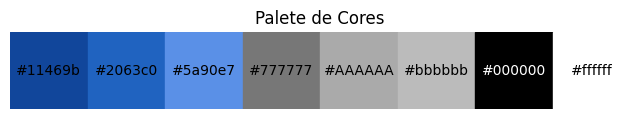

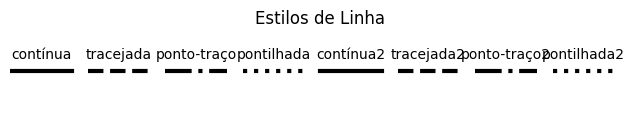

In [3]:
%run "01. Notebooks/00. Configuração/02_Ficheiro Auxiliar.ipynb"

# Visualizar paleta de cores e estilos de linha carregados
if 'mostrar_cores' in globals() and 'PALETA_CORES' in globals():
    mostrar_cores(PALETA_CORES)
if 'mostrar_estilos' in globals() and 'ESTILOS_LINHA' in globals():
    mostrar_estilos(ESTILOS_LINHA)

Carregamento dos Dados

In [4]:
# Carregamento do ficheiro parquet
df_inner_train = pd.read_parquet(ficheiro_inner_train)
df_inner_tunning = pd.read_parquet(ficheiro_inner_tunning)
df_train_full = pd.read_parquet(ficheiro_train_full)
df_test_puro = pd.read_parquet(ficheiro_test_puro)

# Verificação inicial
(df_inner_train.shape, df_inner_tunning.shape, df_train_full.shape, df_test_puro.shape)

((5970843, 11), (1534395, 11), (7505238, 11), (1292514, 11))

Modelo Splines

In [5]:
# Definição necessária para carregar o modelo Splines treinado
# (classe usada no pickle do pipeline)
class TensorBSplineFeatures(BaseEstimator, TransformerMixin):
    """
    Gera features por produto-tensor de B-splines em duas dimensões (m, T).

    Parâmetros principais:
      n_knots_m, n_knots_t : nº de nós por dimensão
      degree               : grau do B-spline (3 = cúbico)
      include_bias         : inclui termo de bias das bases
      knots_mode           : 'quantile' (preferido) ou 'uniform' (fallback)
      extrapolation        : 'linear' recomendado
      with_scaler          : standardizar inputs antes das bases
    """
    def __init__(
        self,
        n_knots_m: int = 8,
        n_knots_t: int = 6,
        degree: int = 3,
        include_bias: bool = False,
        knots_mode: str = "quantile",
        extrapolation: str = "linear",
        with_scaler: bool = True,
    ):
        self.n_knots_m = n_knots_m
        self.n_knots_t = n_knots_t
        self.degree = degree
        self.include_bias = include_bias
        self.knots_mode = knots_mode
        self.extrapolation = extrapolation
        self.with_scaler = with_scaler

        self.scaler_m_: Optional[StandardScaler] = None
        self.scaler_t_: Optional[StandardScaler] = None
        self.spline_m_: Optional[SplineTransformer] = None
        self.spline_t_: Optional[SplineTransformer] = None
        self.knots_mode_m_: Optional[str] = None
        self.knots_mode_t_: Optional[str] = None
        self.n_out_m_: Optional[int] = None
        self.n_out_t_: Optional[int] = None

    def _fit_single(self, x: np.ndarray, n_knots: int, label: str) -> Tuple[Optional[StandardScaler], SplineTransformer, str, int]:
        scaler = None
        x_fit = x
        if self.with_scaler:
            scaler = StandardScaler()
            x_fit = scaler.fit_transform(x)

        knots_mode_used = self.knots_mode
        try:
            spline = SplineTransformer(
                n_knots=n_knots,
                degree=self.degree,
                include_bias=self.include_bias,
                extrapolation=self.extrapolation,
                knots=self.knots_mode,
            )
            B = spline.fit_transform(x_fit)
        except TypeError:
            knots_mode_used = "uniform"
            spline = SplineTransformer(
                n_knots=n_knots,
                degree=self.degree,
                include_bias=self.include_bias,
                extrapolation=self.extrapolation,
            )
            B = spline.fit_transform(x_fit)

        n_out = B.shape[1]
        return scaler, spline, knots_mode_used, n_out

    def fit(self, X: np.ndarray, y: Optional[np.ndarray] = None):
        X = np.asarray(X)
        if X.ndim != 2 or X.shape[1] != 2:
            raise ValueError("TensorBSplineFeatures espera X com shape (n_amostras, 2): colunas [m, T].")

        m = X[:, [0]]
        t = X[:, [1]]

        self.scaler_m_, self.spline_m_, self.knots_mode_m_, self.n_out_m_ = self._fit_single(m, self.n_knots_m, "m")
        self.scaler_t_, self.spline_t_, self.knots_mode_t_, self.n_out_t_ = self._fit_single(t, self.n_knots_t, "t")
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        if any(obj is None for obj in [self.spline_m_, self.spline_t_]):
            raise RuntimeError("Transformer não foi ajustado. Chama .fit primeiro.")

        m = X[:, [0]]
        t = X[:, [1]]

        if self.with_scaler:
            m = self.scaler_m_.transform(m)
            t = self.scaler_t_.transform(t)

        Bm = self.spline_m_.transform(m)
        Bt = self.spline_t_.transform(t)

        Xs = np.einsum('ij,ik->ijk', Bm, Bt).reshape(Bm.shape[0], -1)
        return Xs

# --- Helpers para carregar e aplicar o modelo Splines ---

def load_splines(model_path: str = SPLINES_MODEL_PATH_FINAL, meta_path: str = SPLINES_META_PATH_FINAL):
    model = joblib.load(model_path)
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
    return model, meta


def apply_splines(df: pd.DataFrame, model, features=("log_moneyness", "T"), pred_col="ivs_splines"):
    cols = list(features)
    faltam = [c for c in cols if c not in df.columns]
    if faltam:
        raise ValueError(f"Colunas em falta para Splines: {faltam}")
    X = df[cols].to_numpy(dtype=float)
    y_hat = model.predict(X).astype("float32")
    out = df.copy()
    out[pred_col] = y_hat
    return out

# === SPLINES: carregar modelo e gerar ivs_splines + residuo (inner sets) ===

# 1) Carregar Splines final
splines_model, splines_meta = load_splines(SPLINES_MODEL_PATH_FINAL, SPLINES_META_PATH_FINAL)
print("[Splines] Modelo carregado.")

# 2) Aplicar em inner_train e inner_tunning
_df_in_spl  = apply_splines(df_inner_train,   splines_model, features=("log_moneyness", "T"), pred_col="ivs_splines")
_df_va_spl  = apply_splines(df_inner_tunning, splines_model, features=("log_moneyness", "T"), pred_col="ivs_splines")
_df_trfull_spl = apply_splines(df_train_full, splines_model, features=("log_moneyness", "T"), pred_col="ivs_splines")
_df_test_spl   = apply_splines(df_test_puro,  splines_model, features=("log_moneyness", "T"), pred_col="ivs_splines")

# 3) Calcular resíduos (modelo − teórico)
_df_in_spl["residuo"] = _df_in_spl["iv_teorica"].astype("float32") - _df_in_spl["ivs_splines"].astype("float32")
_df_va_spl["residuo"] = _df_va_spl["iv_teorica"].astype("float32") - _df_va_spl["ivs_splines"].astype("float32")
_df_trfull_spl["residuo"] = _df_trfull_spl["iv_teorica"].astype("float32") - _df_trfull_spl["ivs_splines"].astype("float32")
_df_test_spl["residuo"] = _df_test_spl["iv_teorica"].astype("float32") - _df_test_spl["ivs_splines"].astype("float32")

# 4) Guardar cópias de trabalho
df_inner_train = _df_in_spl
df_inner_tunning = _df_va_spl
df_train_full = _df_trfull_spl
df_test_puro = _df_test_spl

print("✔️ ivs_splines e residuo calculados.")
display(df_inner_train[["ivs_splines","iv_teorica","residuo"]].sample(20))

[Splines] Modelo carregado.
✔️ ivs_splines e residuo calculados.


,ivs_splines,iv_teorica,residuo
480616,0.199864,0.249437,0.049574
4102803,0.245300,0.250007,0.004707
4348442,0.358356,0.354792,-0.003564
4968588,0.306781,0.331885,0.025104
1480820,0.158842,0.177363,0.018521
2622341,0.284637,0.258888,-0.025749
3733157,0.126784,0.176407,0.049623
1902250,0.272487,0.243502,-0.028985
2393031,0.174625,0.196006,0.021381
3379169,0.142197,0.152306,0.010109


Modelização | Setup Inicial

In [6]:
# 0) Config
FEATURES = ("log_moneyness", "T", "option_is_call")
TARGET   = "residuo"
PRED_COL = "residuo_modelo"

# 1) Checks básicos
def _basic_checks(df, features, target):
    cols = list(features) + [target]
    em_falta = [c for c in cols if c not in df.columns]
    if em_falta: raise ValueError(f"Colunas em falta: {em_falta}")

    sub = df[cols]
    nan_counts = sub.isna().sum()
    if nan_counts.any():
        raise ValueError(f"Há NaN nas colunas usadas: {nan_counts[nan_counts>0].to_dict()}")

    inf_detalhe = {}
    for c in cols:
        v = sub[c].to_numpy()
        if not np.isfinite(v).all():
            inf_detalhe[c] = int(np.isinf(v).sum()) + int(np.isnan(v).sum())
    if inf_detalhe:
        raise ValueError(f"Valores não finitos detectados: {inf_detalhe}")
    return sub



# ---------------------------------------------------------------------
# 2) Utilidades de dtype e sampling (RAM‑safe)
def _prepare_xy(df: pd.DataFrame, features: Iterable[str], target: str):
    # Cast eficiente para poupar RAM
    df2 = df.copy()
    for c in features:
        if c == "option_is_call":
            df2[c] = df2[c].astype("int8")
        else:
            df2[c] = df2[c].astype("float32")

    X = df2[list(features)].values 
    y = df2[target].astype("float32").values  
    return X, y

def _make_bins(df: pd.DataFrame, lm_col="log_moneyness", t_col="T", n_lm=30, n_t=12):
    lm_bins = np.linspace(df[lm_col].min(), df[lm_col].max(), n_lm+1)
    t_bins  = np.linspace(df[t_col].min(),  df[t_col].max(),  n_t+1)
    return lm_bins, t_bins

def balanced_sample(df, max_per_bin=5000, lm_col="log_moneyness", t_col="T"):
    df = df.copy()
    lm_q = np.quantile(df[lm_col].values, np.linspace(0, 1, 31))
    t_q  = np.quantile(df[t_col].values,  np.linspace(0, 1, 13))
    lm_edges = np.unique(lm_q)
    t_edges  = np.unique(t_q)
    if lm_edges.size < 3:
        lm_edges = np.linspace(df[lm_col].min(), df[lm_col].max(), 31)
    if t_edges.size < 3:
        t_edges  = np.linspace(df[t_col].min(),  df[t_col].max(),  13)

    lm_cat = pd.cut(df[lm_col], bins=lm_edges, include_lowest=True, right=False)
    t_cat  = pd.cut(df[t_col],  bins=t_edges,  include_lowest=True, right=False)
    df["_lm_bin"] = lm_cat.cat.codes
    df["_t_bin"]  = t_cat.cat.codes

    out = (df.loc[(df["_lm_bin"]>=0) & (df["_t_bin"]>=0)]
            .groupby(["_lm_bin","_t_bin"], group_keys=False)
            .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=42))
            .drop(columns=["_lm_bin","_t_bin"]))
    return out



# ---------------------------------------------------------------------
# ======================================
# 05 — XGBoost (modelo #5)
# ======================================

from __future__ import annotations
import os, json, joblib, numpy as np, pandas as pd
from typing import Iterable, Tuple
from datetime import datetime, timezone

from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance

# ---------------------------------------------------------------------
# 3) Construção do modelo base (GPU/CPU)
def build_xgb(params: dict | None = None, use_gpu: bool = True) -> XGBRegressor:
    base = dict(
        objective="reg:squarederror",
        eval_metric="rmse",
        n_estimators=2000,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=5,
        gamma=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        reg_alpha=0.0,
        random_state=42,
        n_jobs=-1,
        tree_method="hist",                 # <- SEMPRE 'hist'
        device=("cuda" if use_gpu else "cpu"),  # <- e aqui escolhes GPU/CPU
    )
    if params:
        base.update(params)
        if "tree_method" in base and base["tree_method"] != "hist":
            base["tree_method"] = "hist"
    return XGBRegressor(**base)


# ---------------------------------------------------------------------
# 4) Tuning (random search simples + early stopping)
def _rmse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    diff = (y_true - y_pred).astype("float64")
    return float(np.sqrt(np.mean(diff * diff)))

def sample_param_space(n_samples: int, rng: int = 42) -> list[dict]:
    import random
    rnd = random.Random(rng)
    
    # # run 1
    # n_choices = [1600, 2000, 2400, 3000]

    # #run 2
    # n_choices = [2000, 3000, 4000, 6000]

    # # run 3
    # n_choices = [3000, 4000, 6000, 8000, 10000]

    # run 4
    # n_choices = [6000, 8000, 10000]

    # run 5
    n_choices = [4000, 5000, 6000]

    out = []
    for _ in range(n_samples):
        cfg = {
            # run 1
            # "max_depth":        rnd.choice([3, 4, 5]),
            # "min_child_weight": rnd.choice([5, 7, 9, 11]),
            # "gamma":            rnd.uniform(0.05, 0.30),
            # "subsample":        rnd.uniform(0.65, 0.85),
            # "colsample_bytree": rnd.uniform(0.65, 0.85),
            # "learning_rate":    rnd.uniform(0.020, 0.040),
            # "reg_lambda":       rnd.uniform(1.0, 6.0),
            # "reg_alpha":        rnd.uniform(0.10, 0.90),
            # "n_estimators":     rnd.choice(n_choices),

            # # run 2
            # "max_depth":        rnd.choice([4, 5, 6, 7]),
            # "min_child_weight": rnd.choice([5, 7, 9, 11, 13]),
            # "gamma":            rnd.uniform(0.05, 0.50),
            # "subsample":        rnd.uniform(0.60, 0.85),
            # "colsample_bytree": rnd.uniform(0.60, 0.85),
            # "learning_rate":    rnd.uniform(0.018, 0.035),
            # "reg_lambda":       rnd.uniform(3.0, 8.0),
            # "reg_alpha":        rnd.uniform(0.30, 1.20),
            # "n_estimators":     rnd.choice(n_choices),

            # # run 3
            # "base_score":      0.0,
            # "max_bin": rnd.choice([128, 256, 512]),

            # "max_depth":        rnd.choice([3, 4, 5, 6]),
            # "min_child_weight": rnd.choice([9, 11, 13, 15]),
            # "gamma":            rnd.uniform(0.010, 0.60),
            # "subsample":        rnd.uniform(0.60, 0.85),
            # "colsample_bytree": rnd.uniform(0.60, 0.85),
            # "learning_rate":    rnd.uniform(0.018, 0.032),
            # "reg_lambda":       rnd.uniform(4.0, 10.0),
            # "reg_alpha":        rnd.uniform(0.50, 1.50),
            # "n_estimators":     rnd.choice(n_choices),

            # # run 4
            # "base_score":      0.0,
            # "max_bin": rnd.choice([256, 512]),

            # "max_depth":        rnd.choice([3, 4, 5, 6]),
            # "min_child_weight": rnd.choice([9, 11, 13, 15]),
            # "gamma":            rnd.uniform(0.010, 0.60),
            # "subsample":        rnd.uniform(0.60, 0.85),
            # "colsample_bytree": rnd.uniform(0.60, 0.85),
            # "learning_rate":    rnd.uniform(0.010, 0.020),
            # "reg_lambda":       rnd.uniform(4.0, 10.0),
            # "reg_alpha":        rnd.uniform(0.50, 1.50),
            # "n_estimators":     rnd.choice(n_choices),

            # run 5
            "base_score":      0.0,
            "max_bin": rnd.choice([256, 512]),

            "max_depth":        rnd.choice([3, 4, 5]),
            "min_child_weight": rnd.choice([5, 7, 9, 11]),
            "gamma":            rnd.uniform(0.05, 0.30),
            "subsample":        rnd.uniform(0.65, 0.85),
            "colsample_bytree": rnd.uniform(0.65, 0.85),
            "learning_rate":    rnd.uniform(0.020, 0.040),
            "reg_lambda":       rnd.uniform(1.0, 6.0),
            "reg_alpha":        rnd.uniform(0.10, 0.90),
            "n_estimators":     rnd.choice(n_choices),

        }
        out.append(cfg)
    return out

def tune_xgb(
    df_inner_train: pd.DataFrame,
    df_inner_tunning: pd.DataFrame,
    features: Iterable[str],
    target: str,
    n_iter: int = 40,
    use_balanced_sample: bool = True,
    max_per_bin: int = 5000,
    random_state: int = 42,
    use_gpu: bool = True,
    pred_col: str = "residuo_modelo",
    # pred_col: str = "ivs_modelo",
) -> tuple[dict, int, pd.DataFrame, pd.DataFrame]:
    """
    Random search SEM early stopping:
      - treino: amostra balanceada de inner_train (ou o próprio inner_train)
      - validação: inner_tunning
    Retorna: (best_params, best_iteration (== n_estimators-1), df_inner_train_pred, df_inner_tunning_pred)
    """
    _basic_checks(df_inner_train, features, target)
    _basic_checks(df_inner_tunning, features, target)

    # amostra balanceada para acelerar busca
    train_df = balanced_sample(df_inner_train, max_per_bin=max_per_bin) if use_balanced_sample else df_inner_train

    X_tr_s, y_tr_s = _prepare_xy(train_df,        features, target)
    X_in,  y_in    = _prepare_xy(df_inner_train,  features, target)
    X_va,  y_va    = _prepare_xy(df_inner_tunning,features, target)

    base_params = dict(objective="reg:squarederror", eval_metric="rmse")
    cand_list = sample_param_space(n_iter, rng=random_state)

    best = dict(params=None, best_rmse=np.inf, model=None)
    for i, cand in enumerate(cand_list, 1):
        # evitar paralelismo aninhado
        params_i = {**base_params, **cand, "n_jobs": 1}

        # constrói modelo (GPU/CPU conforme flag)
        model_i = build_xgb(params=params_i, use_gpu=use_gpu)
        model_i.fit(X_tr_s, y_tr_s, verbose=False)

        # avalia na validação
        y_va_hat = model_i.predict(X_va).astype("float32")
        # y_va_hat = np.clip(y_va_hat, 1e-4, 2.0)
        rmse_va = _rmse(y_va, y_va_hat)

        if rmse_va < best["best_rmse"]:
            best.update(params=params_i, best_rmse=rmse_va, model=model_i)

    # melhores parâmetros (limpa n_jobs=1 para treino final)
    best_params = dict(best["params"])
    best_params["n_jobs"] = -1

    # definimos "best_iteration" para manter compatibilidade com o teu fluxo
    best_iteration = int(best_params.get("n_estimators", 1)) - 1

    # Refit no inner_train completo com os melhores parâmetros
    best_refit = build_xgb(best_params, use_gpu=use_gpu)
    best_refit.fit(X_in, y_in, verbose=False)

    # Previsões (clip apenas nas previsões)
    # y_hat_in = np.clip(best_refit.predict(X_in).astype("float32"), 1e-4, 2.0)
    # y_hat_va = np.clip(best_refit.predict(X_va).astype("float32"), 1e-4, 2.0)
    y_hat_in = best_refit.predict(X_in).astype("float32")   # sem clip
    y_hat_va = best_refit.predict(X_va).astype("float32")   # sem clip  


    df_inner_train_pred   = df_inner_train.copy()
    df_inner_tunning_pred = df_inner_tunning.copy()
    df_inner_train_pred[pred_col]   = y_hat_in
    df_inner_tunning_pred[pred_col] = y_hat_va

    return best_params, best_iteration, df_inner_train_pred, df_inner_tunning_pred



# ---------------------------------------------------------------------
# 5) Treino final
def train_xgb(
    df_train_full: pd.DataFrame,
    features: Iterable[str],
    target: str,
    best_params: dict | None = None,
    best_iteration: int | None = None,
    use_gpu: bool = True,
    return_in_sample_pred: bool = True,
    # pred_col: str = "ivs_modelo",
    pred_col: str = "residuo_modelo",
) -> tuple[XGBRegressor, dict, pd.DataFrame | None]:
    """
    Treina XGBRegressor em train_full.
    - Se best_iteration for fornecido: define n_estimators = best_iteration (+1 por segurança).
    - Se não houver best_params: usa defaults robustos.
    """
    _basic_checks(df_train_full, features, target)
    X_tr, y_tr = _prepare_xy(df_train_full, features, target)

    params = dict(best_params) if best_params else {}
    if best_iteration is not None:
        params["n_estimators"] = int(best_iteration) + 1
        # margem opcional de +10%:
        params["n_estimators"] = int(max(params["n_estimators"], round((best_iteration + 1) * 1.10)))
    

    xgb = build_xgb(params, use_gpu=use_gpu)
    xgb.fit(X_tr, y_tr, verbose=False)

    meta = {
        "model_type": "XGBRegressor",
        "features": list(features),
        "target": target,
        "n_obs": int(X_tr.shape[0]),
        "params": xgb.get_params(),
        "trained_at": datetime.now(timezone.utc).isoformat() + "Z",
        "date_min": str(df_train_full["quote_date"].min()) if "quote_date" in df_train_full.columns else None,
        "date_max": str(df_train_full["quote_date"].max()) if "quote_date" in df_train_full.columns else None,
        "best_iteration": int(best_iteration) if best_iteration is not None else None,
    }

    df_train_pred = None
    if return_in_sample_pred:
        y_hat_tr = xgb.predict(X_tr).astype("float32")
        # y_hat_tr = np.clip(y_hat_tr, 1e-4, 2.0)
        df_train_pred = df_train_full.copy()
        df_train_pred[pred_col] = y_hat_tr

    return xgb, meta, df_train_pred


# ---------------------------------------------------------------------
# 6) Aplicação do modelo
def apply_xgb_model(
    df: pd.DataFrame,
    model: XGBRegressor,
    features: Iterable[str],
    # pred_col: str = "ivs_modelo",
    pred_col: str = "residuo_modelo",
    clip_pred: bool = False,
    # clip_min: float = 1e-4,
    clip_min: float = -2.0,
    clip_max: float = 2.0,
) -> pd.DataFrame:
    faltam = [c for c in features if c not in df.columns]
    if faltam:
        raise ValueError(f"Colunas em falta: {faltam}")
    X, _ = _prepare_xy(df.assign(__y=0.0), features, "__y")
    y_hat = model.predict(X).astype("float32")
    if clip_pred:
        y_hat = np.clip(y_hat, clip_min, clip_max)
    out = df.copy()
    out[pred_col] = y_hat
    return out


# ---------------------------------------------------------------------
# 7) Importâncias
def xgb_importances(
    model: XGBRegressor,
    df_ref: pd.DataFrame,
    features: Iterable[str],
    target: str,
    n_repeats: int = 5,
    max_rows: int | None = 200_000,   # <- novo
) -> pd.DataFrame:
    feats = list(features)

    booster = model.get_booster()
    gain_map = booster.get_score(importance_type="gain")
    gain_vals = [gain_map.get(f"f{i}", 0.0) for i in range(len(feats))]

    # Amostra para permutation (acelera muito em datasets enormes)
    ref = df_ref
    if (max_rows is not None) and (len(ref) > max_rows):
        ref = ref.sample(max_rows, random_state=42)

    X_ref, y_ref = _prepare_xy(ref, feats, target)
    perm = permutation_importance(model, X_ref, y_ref, n_repeats=n_repeats, random_state=42, n_jobs=-1)

    df_imp = pd.DataFrame({
        "feature": feats,
        "gain_importance": gain_vals,
        "permutation_importance": perm.importances_mean,
        "permutation_std": perm.importances_std,
    }).sort_values(["permutation_importance", "gain_importance"], ascending=False).reset_index(drop=True)

    return df_imp



# ---------------------------------------------------------------------
# 8) Conveniências de IO para parâmetros ótimos (usando os teus paths)
def save_best_params(best_params: dict, best_iteration: int | None, best_path: str):
    payload = dict(best_params=best_params, best_iteration=best_iteration)
    with open(best_path, "w", encoding="utf-8") as f:
        json.dump(payload, f, ensure_ascii=False, indent=2)

def load_best_params(best_path: str) -> tuple[dict | None, int | None]:
    if not os.path.exists(best_path):
        return None, None
    with open(best_path, "r", encoding="utf-8") as f:
        d = json.load(f)
    return d.get("best_params"), d.get("best_iteration")



# ---------------------------------------------------------------------
# 9) Guardar / carregar modelo
def save_model(model, meta: dict, model_path: str, meta_path: str):
    """Guarda o pipeline treinado (joblib) e o dicionário meta (JSON) nos caminhos indicados."""
    joblib.dump(model, model_path)
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

def load_model(model_path: str, meta_path: str):
    """Carrega o pipeline treinado e o meta JSON a partir dos caminhos indicados; devolve (model, meta)."""
    model = joblib.load(model_path)
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
    return model, meta

Modelização | Tuning (inner_tunning)

In [7]:
# --- 1) TUNING em inner (random search; sem ES) ---
best_params, best_it, df_inner_train_pred, df_inner_tunning_pred = tune_xgb(
    df_inner_train, df_inner_tunning,
    FEATURES, TARGET,
    n_iter=120,                 # ajusta se quiseres mais/menos busca
    use_balanced_sample=True,  # usa amostra por bins para acelerar
    max_per_bin=5000,
    use_gpu=True,
    pred_col=PRED_COL
)

print("Melhores parâmetros:", best_params)
print("best_it (≈ n_estimators-1):", best_it)

# (Opcional) guardar melhores parâmetros para reuso/reprodutibilidade
save_best_params(best_params, best_it, BEST_PARAMS)

C:\Users\sergi\AppData\Local\Temp\ipykernel_21292\2527942586.py:66: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=42))
c:\Users\sergi\Desktop\Tese - IVS with ML Techniques\venv_tese\Lib\site-packages\xgboost\core.py:729: UserWarning: [19:59:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before 

Melhores parâmetros: {'objective': 'reg:squarederror', 'eval_metric': 'rmse', 'base_score': 0.0, 'max_bin': 256, 'max_depth': 5, 'min_child_weight': 11, 'gamma': 0.277346909606973, 'subsample': 0.7104380349058501, 'colsample_bytree': 0.7316591711590825, 'learning_rate': 0.022795540250144422, 'reg_lambda': 5.731307664409731, 'reg_alpha': 0.3434916674848042, 'n_estimators': 5000, 'n_jobs': -1}
best_it (≈ n_estimators-1): 4999


Modelização | Refit best params e calibração sobre inner_training e inner_tunning

In [8]:
# (Opcional) guardar um modelo “inner_refit” (útil para auditoria)
xgb_inner, meta_inner, _ = train_xgb(
    df_inner_train, FEATURES, TARGET,
    best_params=best_params,
    best_iteration=best_it,
    use_gpu=True,
    return_in_sample_pred=False,
    pred_col=PRED_COL
)
save_model(xgb_inner, meta_inner, MODEL_PATH_INNER, META_PATH_INNER)

Modelização | Training Final (train_full)

In [9]:
# --- 2) Treino final em train_full com best params/iter ---
xgb_final, meta_final, df_train_full_pred = train_xgb(
    df_train_full, FEATURES, TARGET,
    best_params=best_params,
    best_iteration=best_it,
    use_gpu=True,
    return_in_sample_pred=True,   # para obter df_train_full_pred
    pred_col=PRED_COL
)
save_model(xgb_final, meta_final, MODEL_PATH_FINAL, META_PATH_FINAL)

Modelização | Teste (test_puro)

In [10]:
# --- 3) Aplicar ao test_puro (e a qualquer outro split) ---
df_test_puro_pred = apply_xgb_model(
    df_test_puro, xgb_final, FEATURES,
    pred_col=PRED_COL,
    clip_pred=False   # sem clip
)

print("✔️ ivs_modelo criado em test_puro.")

✔️ ivs_modelo criado em test_puro.


Importância dos Features

In [11]:
# -------------------------------------------------------------
# IMPORTÂNCIAS XGBOOST (GAIN + PERMUTATION)
# -------------------------------------------------------------

# Recalcular importâncias com base no modelo treinado
df_import = xgb_importances(
    model=xgb_final,
    df_ref=df_test_puro,
    features=FEATURES,
    target=TARGET,
    n_repeats=5,
    max_rows=200_000  # acelera sem perda substancial de robustez
)

# Visualização rápida
display(df_import)

,feature,gain_importance,permutation_importance,permutation_std
0,option_is_call,82.997002,0.369386,0.001350
1,log_moneyness,4.632439,0.210946,0.001894
2,T,1.866795,0.026144,0.000285


Calibração linear (afina em inner_tunning e aplica em test_puro)

In [12]:
# === Calibração linear dos resíduos + criação dos DFs calibrados (bloco único) ===
# Premissas:
# - PRED_COL = "residuo_modelo"
# - TARGET   = "residuo"
# - LINEAR_ADJUST = caminho para guardar (a,b)
# - Já existem: df_inner_train_pred, df_inner_tunning_pred, df_train_full_pred, df_test_puro_pred
# - df_inner_tunning_pred e df_test_puro_pred têm a coluna 'ivs_splines'

# ---------------------------
# 0) Sanity checks mínimos
# ---------------------------
assert PRED_COL in df_inner_tunning_pred.columns, "PRED_COL não existe em df_inner_tunning_pred"
assert PRED_COL in df_test_puro_pred.columns,     "PRED_COL não existe em df_test_puro_pred"
assert TARGET   in df_inner_tunning_pred.columns, "TARGET não existe em df_inner_tunning_pred"
assert "ivs_splines" in df_inner_tunning_pred.columns and "ivs_splines" in df_test_puro_pred.columns, \
       "Falta coluna 'ivs_splines' para construir ivs_modelo"

# ---------------------------
# 1) Ajuste de calibração em inner_tunning: residuo_real ≈ a + b * residuo_previsto
# ---------------------------
X_cal = df_inner_tunning_pred[[PRED_COL]].to_numpy(dtype="float64")  # (n,1)
y_cal = df_inner_tunning_pred[TARGET].to_numpy(dtype="float64")

lin = LinearRegression(fit_intercept=True).fit(X_cal, y_cal)
a = float(lin.intercept_)
b = float(lin.coef_[0])
print(f"Calibração (inner_tunning): residuo ≈ {a:.6f} + {b:.6f} * residuo_hat")

# Guardar parâmetros (a,b)
os.makedirs(os.path.dirname(LINEAR_ADJUST), exist_ok=True)
with open(LINEAR_ADJUST, "w", encoding="utf-8") as f:
    json.dump({
        "type": "linear",
        "a": a, "b": b,
        "fitted_on": "inner_tunning",
        "n_obs": int(len(df_inner_tunning_pred))
    }, f, ensure_ascii=False, indent=2)
print(f"✔️ Parâmetros de calibração guardados em {LINEAR_ADJUST}")

# ---------------------------
# 2) Utilitário: cria uma CÓPIA calibrada (não altera DF original)
#    - calibra RESÍDUOS (sem clip)
#    - constrói IV final (clip apenas na IV)
# ---------------------------
def make_calibrated_copy(df: pd.DataFrame,
                         pred_res_col: str = "residuo_modelo",
                         iv_base_col: str = "ivs_splines",
                         a: float = 0.0, b: float = 1.0,
                         iv_clip: tuple[float,float] = (1e-4, 2.0)) -> pd.DataFrame:
    out = df.copy()
    # guarda coluna raw dos resíduos previstos (para comparação futura)
    raw_col = f"{pred_res_col}_raw"
    if raw_col not in out.columns:
        out[raw_col] = out[pred_res_col].astype("float32")

    # resíduos calibrados: a + b * res_hat   (SEM clip aqui)
    resid_cal = (a + b * out[pred_res_col].to_numpy(dtype=np.float32)).astype("float32")
    out[f"{pred_res_col}_cal"] = resid_cal

    # IV final calibrada = ivs_splines + residuo_modelo_cal   (clip só na IV)
    ivs_raw = (out[iv_base_col].to_numpy(dtype=np.float32) + resid_cal).astype("float32")
    out["ivs_modelo_raw"] = ivs_raw
    out["ivs_modelo"] = np.clip(ivs_raw, iv_clip[0], iv_clip[1]).astype("float32")
    return out

# ---------------------------
# 3) Criar APENAS os DFs calibrados para inner_tunning e test_puro
#    (os 4 DFs originais sem calibração mantêm-se inalterados)
# ---------------------------
df_inner_tunning_pred_cal = make_calibrated_copy(
    df_inner_tunning_pred, pred_res_col=PRED_COL, iv_base_col="ivs_splines", a=a, b=b
)
df_test_puro_pred_cal = make_calibrated_copy(
    df_test_puro_pred,     pred_res_col=PRED_COL, iv_base_col="ivs_splines", a=a, b=b
)

print("✔️ Criados: df_inner_tunning_pred_cal, df_test_puro_pred_cal (com colunas residuo_modelo_cal, ivs_modelo_raw, ivs_modelo)")
print("ℹ️ DFs sem calibração preservados: df_inner_train_pred, df_inner_tunning_pred, df_train_full_pred, df_test_puro_pred")


Calibração (inner_tunning): residuo ≈ -0.004716 + 0.909880 * residuo_hat
✔️ Parâmetros de calibração guardados em 04. Resultados/07. Modelo #7 - Híbrido (XGBoost)/07. Híbrido_XGBoost_linear_adjust.json
✔️ Criados: df_inner_tunning_pred_cal, df_test_puro_pred_cal (com colunas residuo_modelo_cal, ivs_modelo_raw, ivs_modelo)
ℹ️ DFs sem calibração preservados: df_inner_train_pred, df_inner_tunning_pred, df_train_full_pred, df_test_puro_pred


Criar IVS_MODELO nos dataframes finais

In [13]:
# === Lista dos dataframes a atualizar ===
df_dict = dict(
    inner_train=df_inner_train_pred,
    inner_tunning=df_inner_tunning_pred,
    train_full=df_train_full_pred,
    test_puro=df_test_puro_pred,
)

# === Atualizar a coluna ivs_modelo em cada dataframe ===
for nome_df, df in df_dict.items():
    if 'ivs_splines' in df.columns and 'residuo_modelo' in df.columns:
        ivs_raw = df['ivs_splines'] + df['residuo_modelo']
        df['ivs_modelo'] = ivs_raw.clip(lower=1e-4, upper=2.0)
    else:
        print(f"⚠️  Aviso: '{nome_df}' não contém as colunas necessárias para construir 'ivs_modelo'")

Métricas de Avaliação

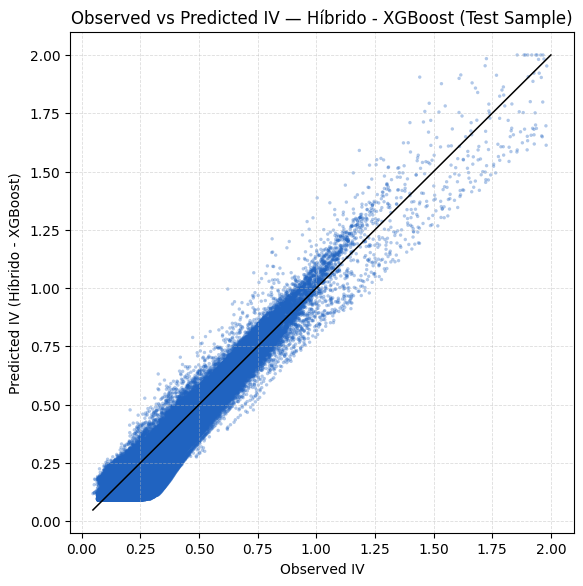

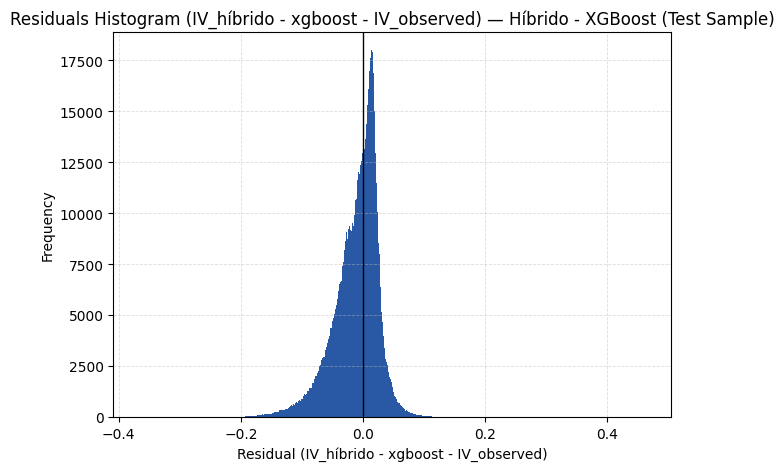

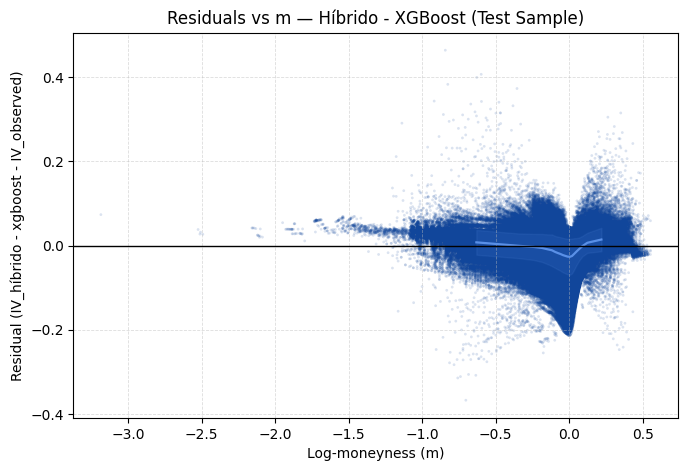

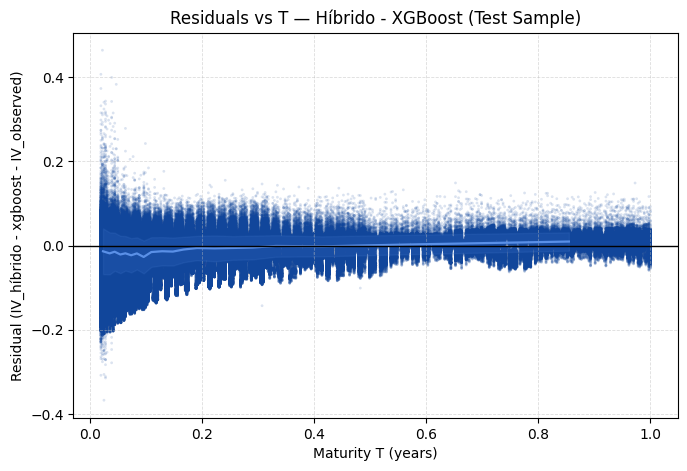

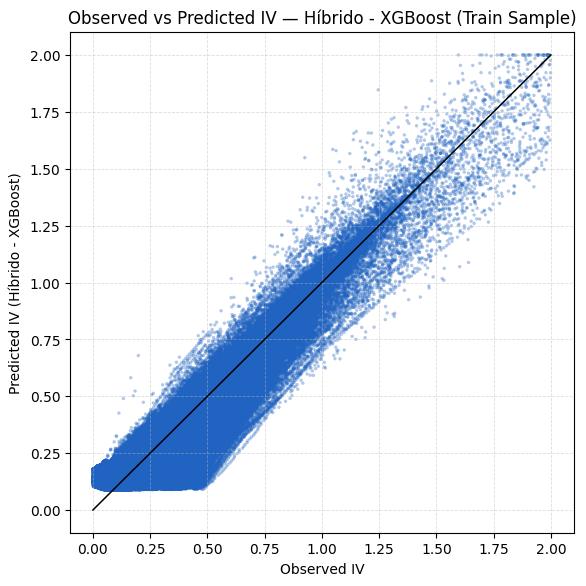

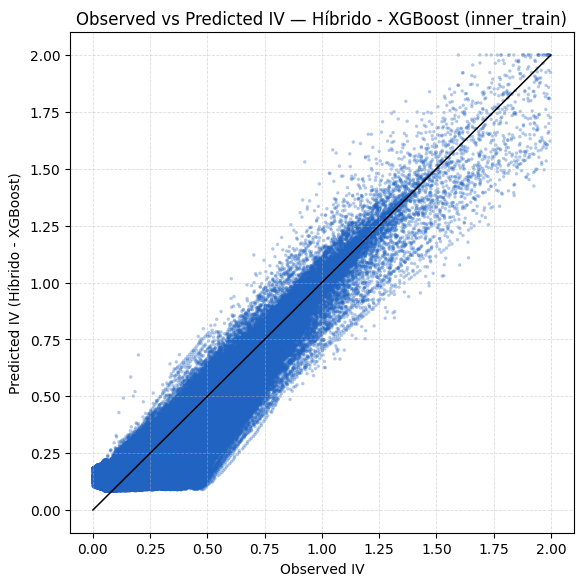

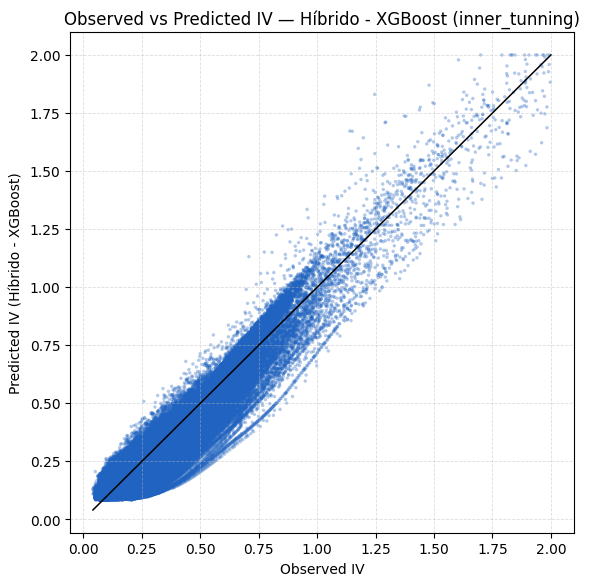

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Híbrido - XGBoost,test_puro,geral,train_full,1292514,0.038772,0.027990,0.019866,0.889247,-1.099944e-02
1,Híbrido - XGBoost,train_full,especifica,train_full,7505238,0.042639,0.029343,0.021986,0.883445,-9.763639e-08
2,Híbrido - XGBoost,Test Sample,geral,train_full,1292514,0.038772,0.027990,0.019866,0.889247,-1.099944e-02
3,Híbrido - XGBoost,Train Sample,especifica,train_full,7505238,0.042639,0.029343,0.021986,0.883445,-9.763639e-08
4,Híbrido - XGBoost,inner_train,especifica,inner_training,5970843,0.044554,0.030636,0.022760,0.872242,-7.358355e-07
5,Híbrido - XGBoost,inner_tunning,especifica,inner_training,1534395,0.034528,0.025452,0.020860,0.924087,4.752214e-03


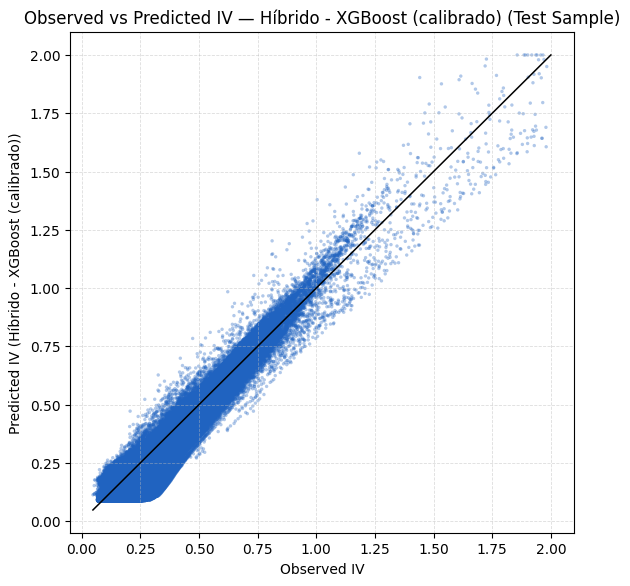

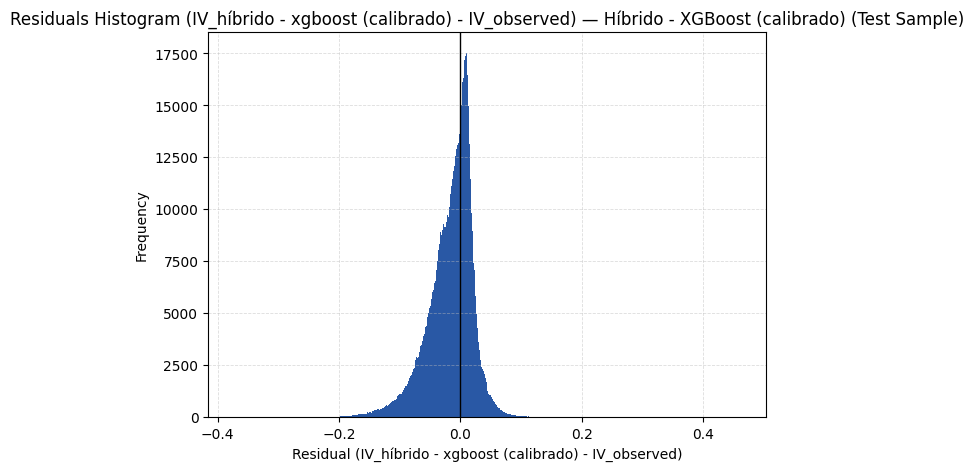

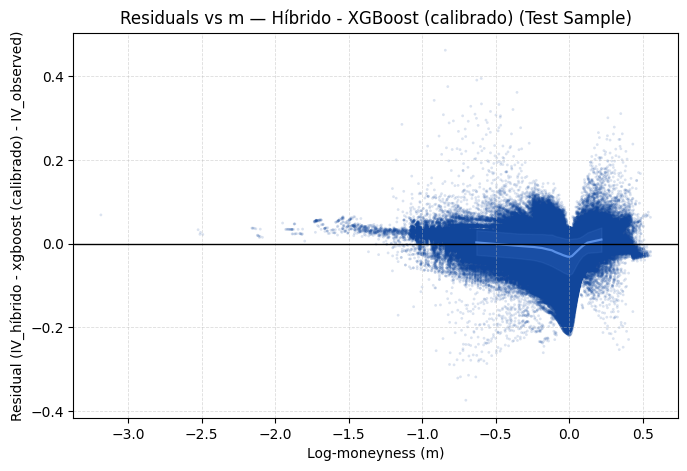

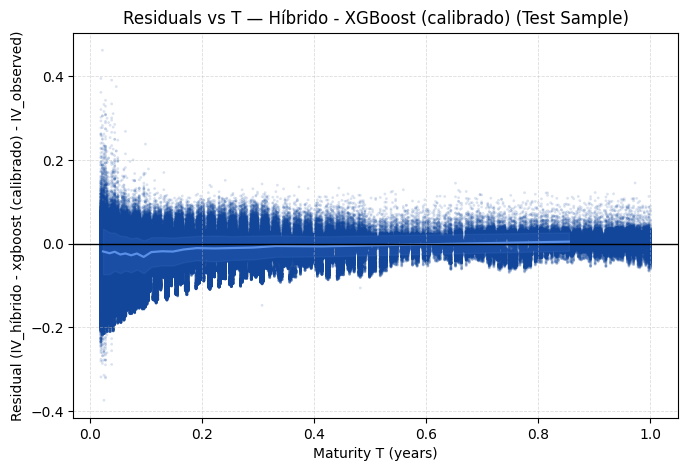

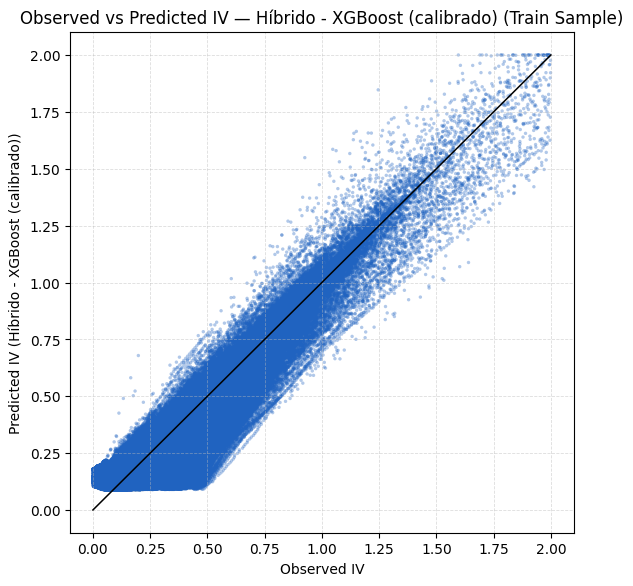

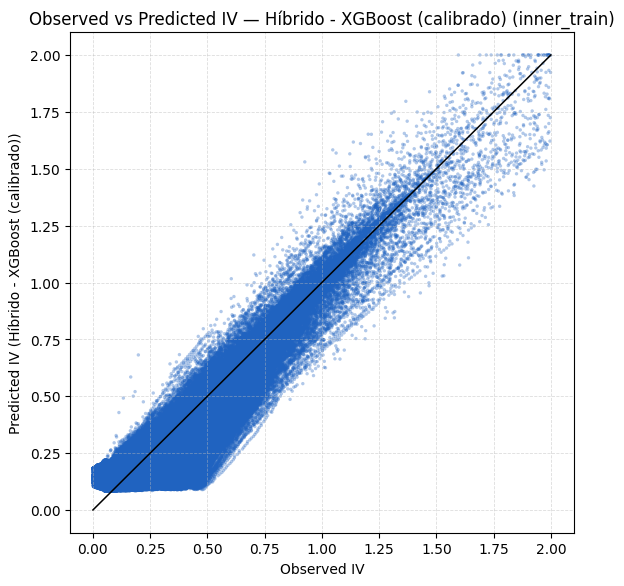

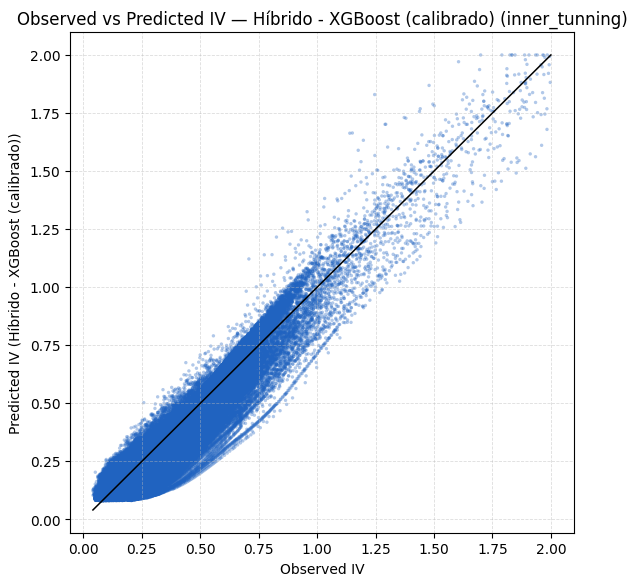

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Híbrido - XGBoost (calibrado),test_puro,geral,train_full,1292514,0.040475,0.028858,0.019623,0.879306,-1.564870e-02
1,Híbrido - XGBoost (calibrado),train_full,especifica,train_full,7505238,0.042639,0.029343,0.021986,0.883445,-9.763639e-08
2,Híbrido - XGBoost (calibrado),Test Sample,geral,train_full,1292514,0.040475,0.028858,0.019623,0.879306,-1.564870e-02
3,Híbrido - XGBoost (calibrado),Train Sample,especifica,train_full,7505238,0.042639,0.029343,0.021986,0.883445,-9.763639e-08
4,Híbrido - XGBoost (calibrado),inner_train,especifica,inner_training,5970843,0.044554,0.030636,0.022760,0.872242,-7.358355e-07
5,Híbrido - XGBoost (calibrado),inner_tunning,especifica,inner_training,1534395,0.034172,0.024246,0.018835,0.925644,-9.826997e-07


,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Híbrido - XGBoost (calibrado),test_puro,geral,train_full,1292514,0.040475,0.028858,0.019623,0.879306,-1.564870e-02
1,Híbrido - XGBoost (calibrado),train_full,especifica,train_full,7505238,0.042639,0.029343,0.021986,0.883445,-9.763639e-08
2,Híbrido - XGBoost (calibrado),Test Sample,geral,train_full,1292514,0.040475,0.028858,0.019623,0.879306,-1.564870e-02
3,Híbrido - XGBoost (calibrado),Train Sample,especifica,train_full,7505238,0.042639,0.029343,0.021986,0.883445,-9.763639e-08
4,Híbrido - XGBoost (calibrado),inner_train,especifica,inner_training,5970843,0.044554,0.030636,0.022760,0.872242,-7.358355e-07


In [14]:
# --- 1) chamar a função run_avaliacoes para versão sem calibração ---
res_rf = run_avaliacoes(
    df_inner_train=df_inner_train_pred,   # contém ivs_modelo
    df_inner_tunning=df_inner_tunning_pred,
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred,
    model="Híbrido - XGBoost",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",
    max_points_scatter=250_000,
    dpi=160,
    display_in_notebook=True
)

res_rf["globais_df"].head()

# --- 2) chamar a função run_avaliacoes para versão com calibração ---
res_rf = run_avaliacoes(
    df_inner_train=df_inner_train_pred,   # contém ivs_modelo
    df_inner_tunning=df_inner_tunning_pred_cal,
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred_cal,
    model="Híbrido - XGBoost (calibrado)",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",
    max_points_scatter=250_000,
    dpi=160,
    display_in_notebook=True
)

res_rf["globais_df"].head()

Visualização Gráfica

IVS Teórica:


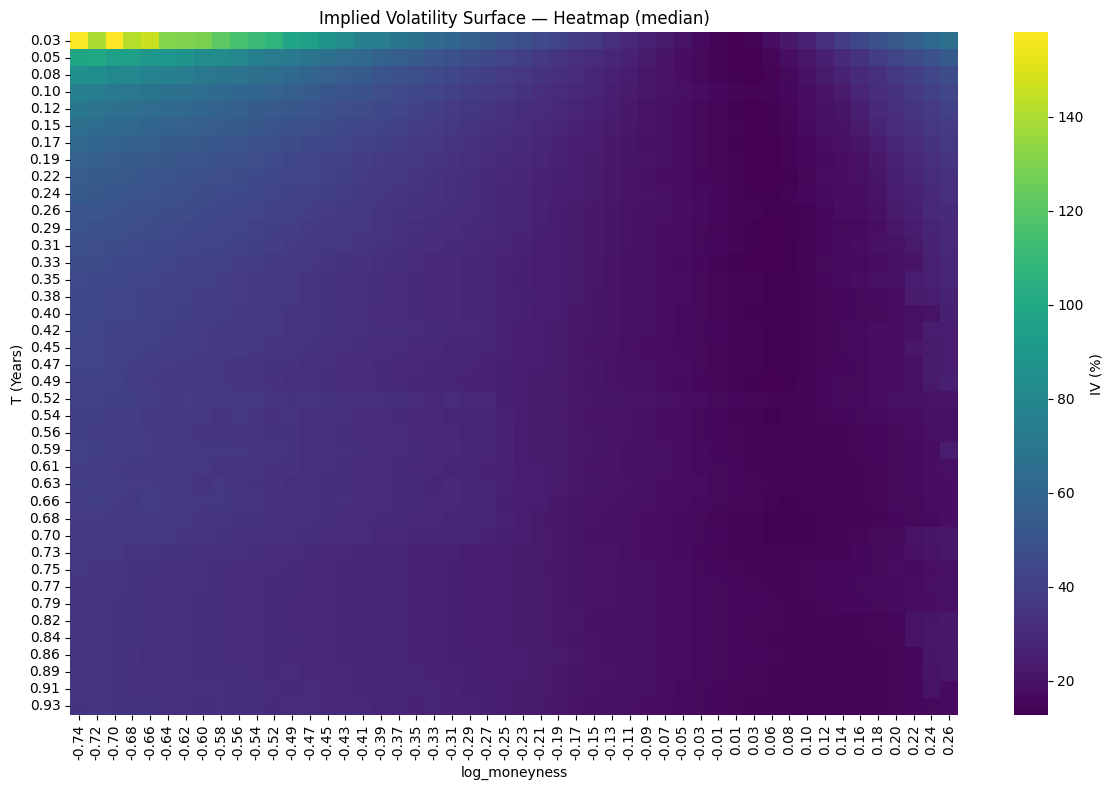

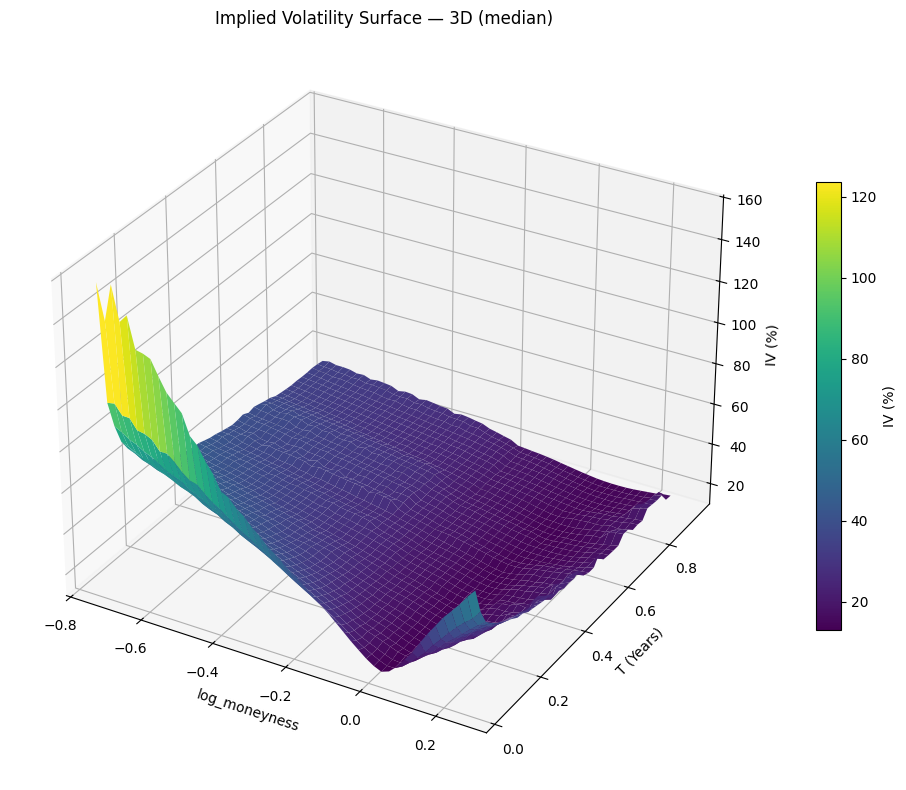

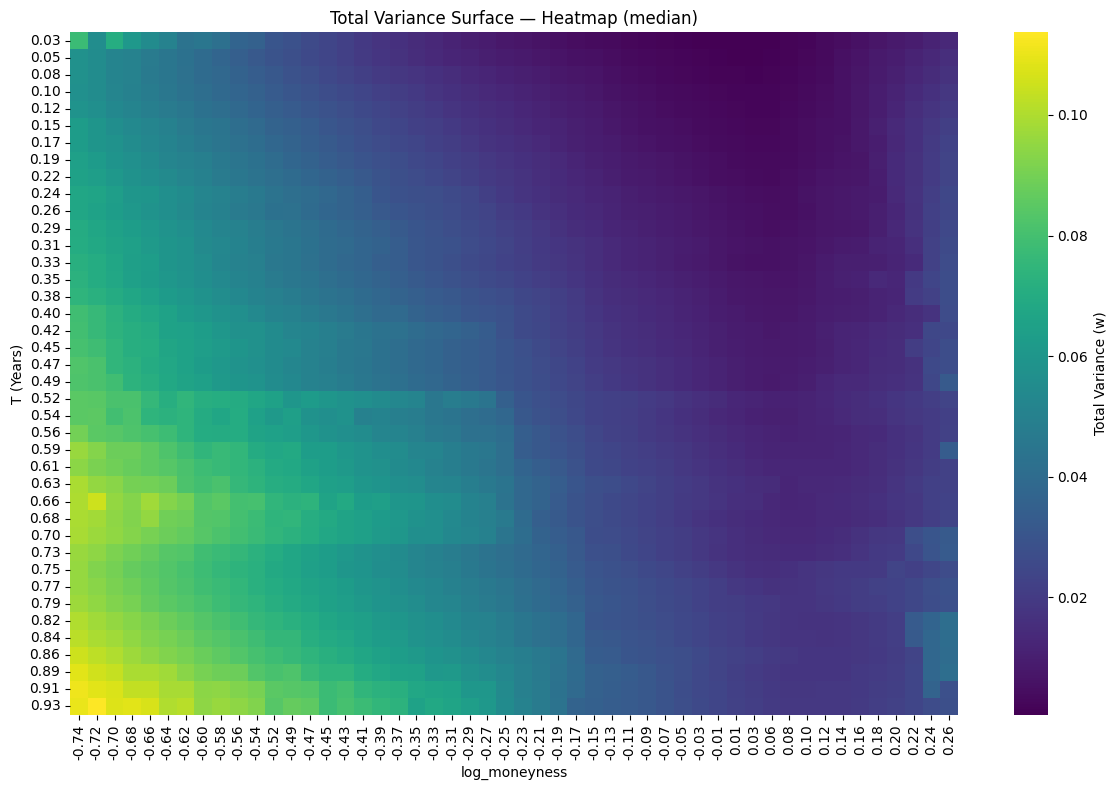

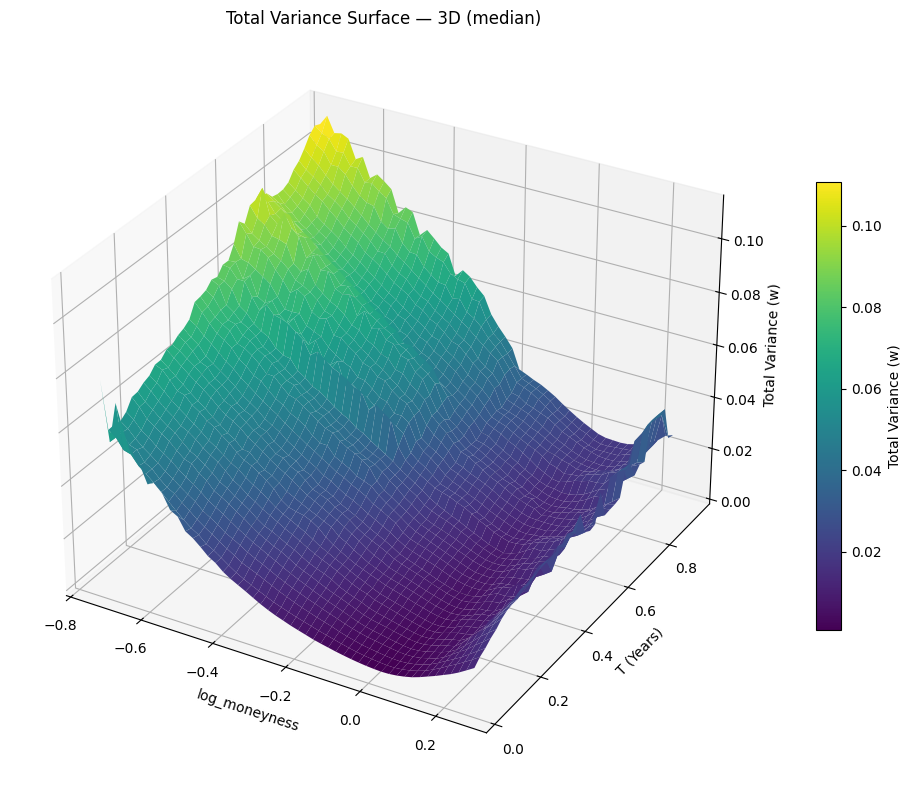

IVS Modelo (não calibrada):


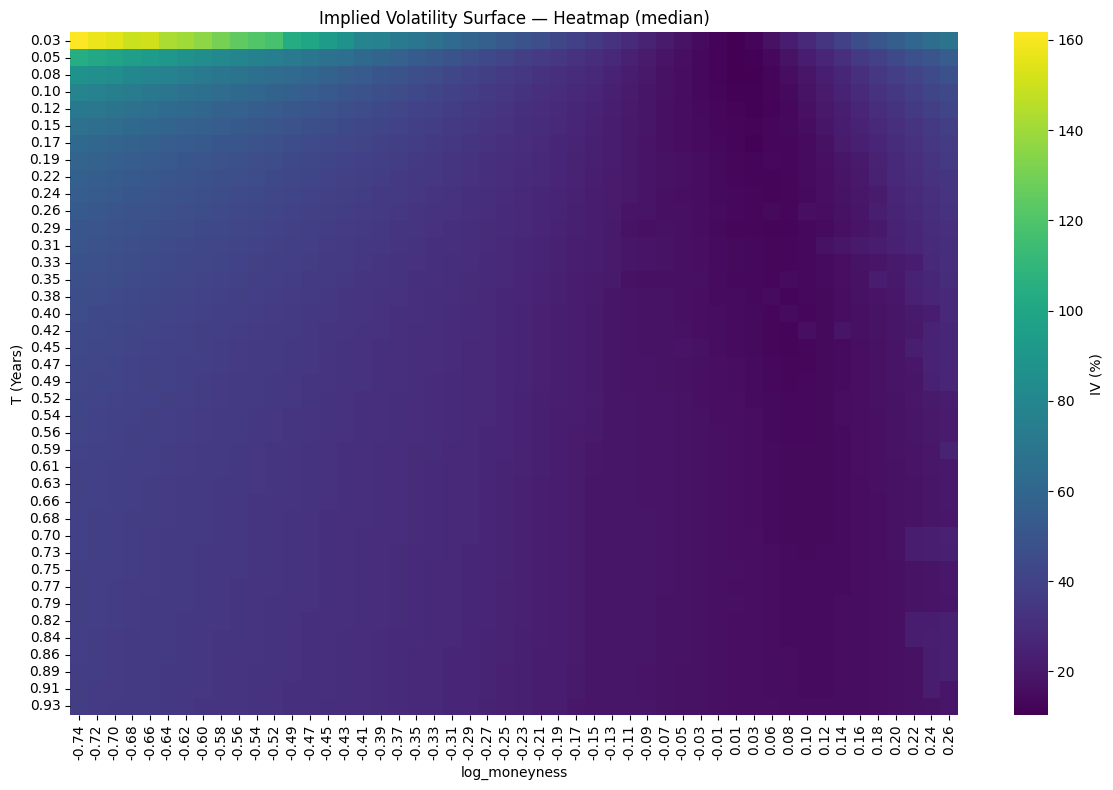

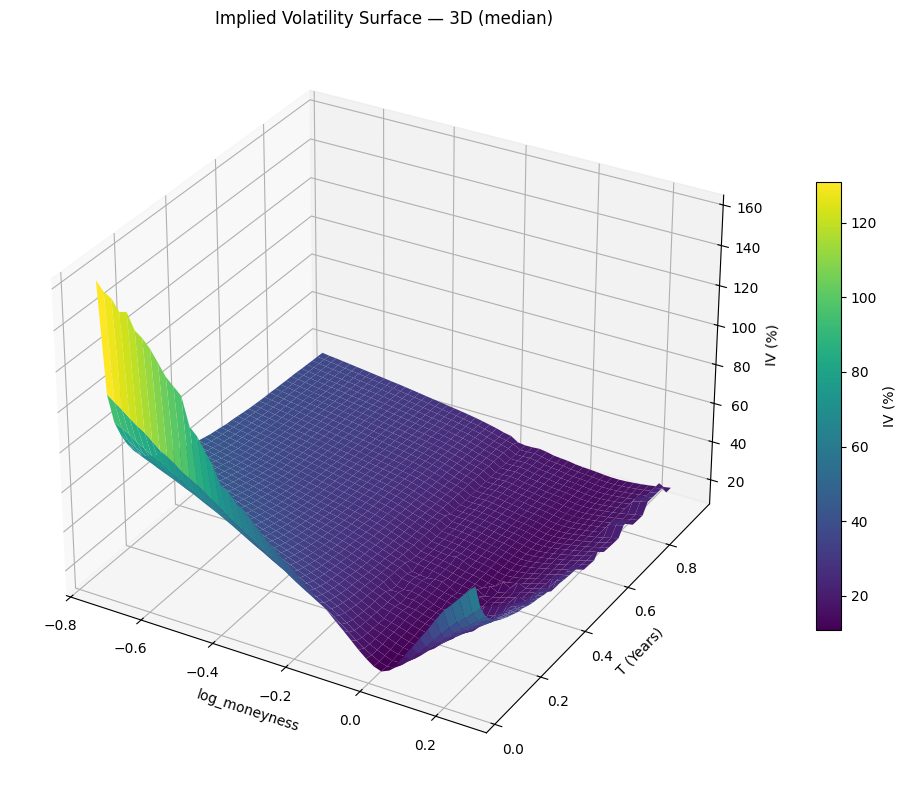

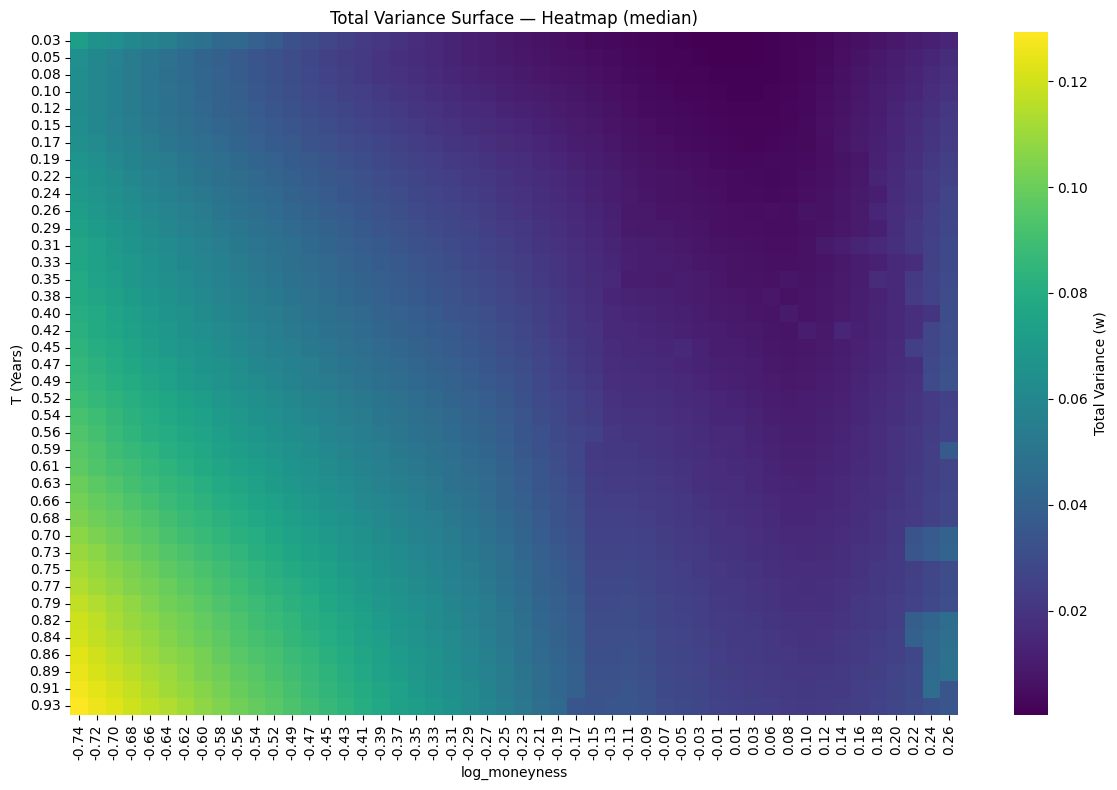

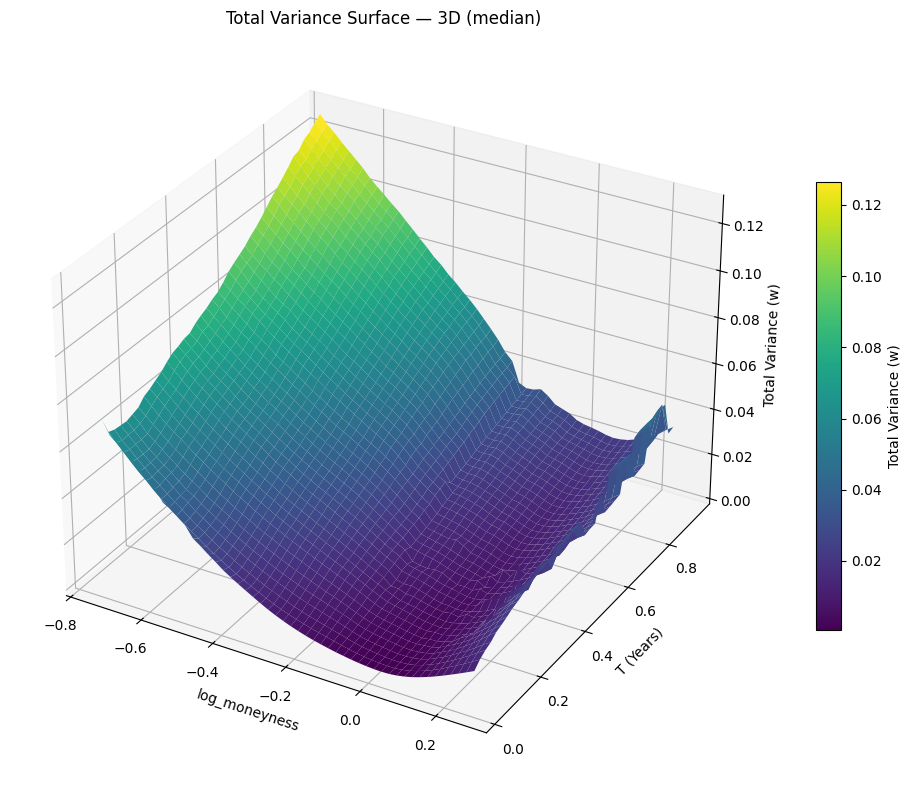

IVS Modelo (calibrada):


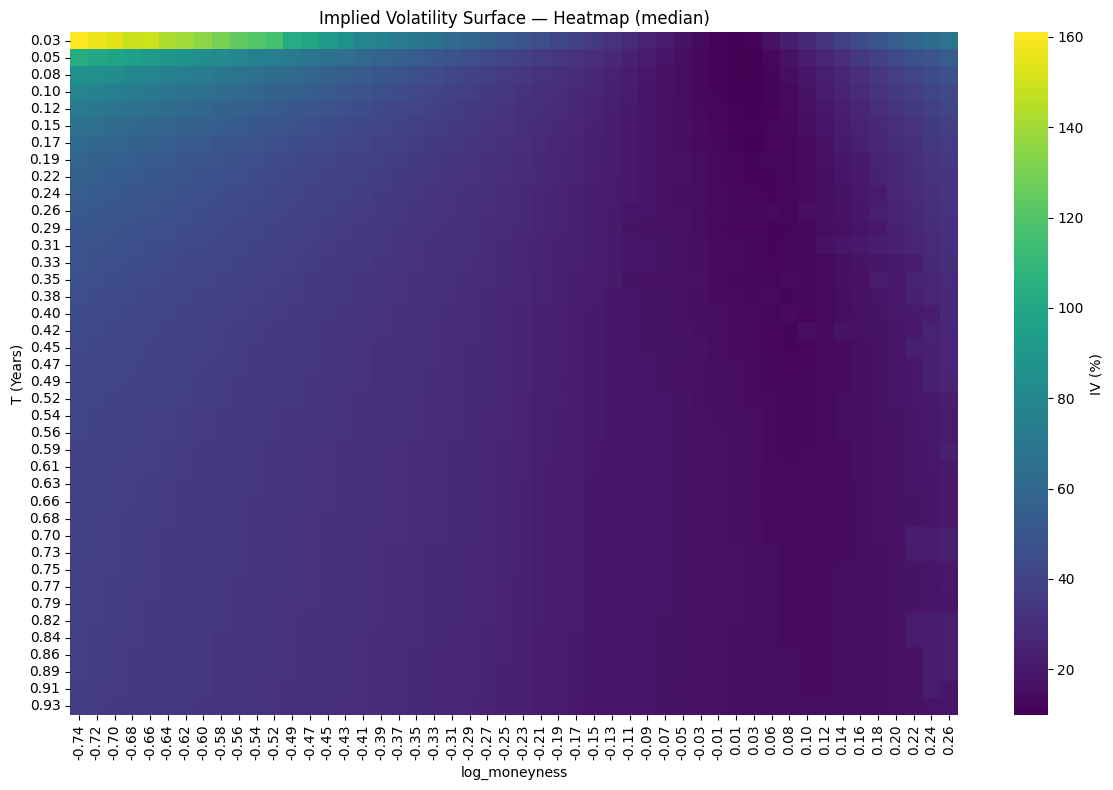

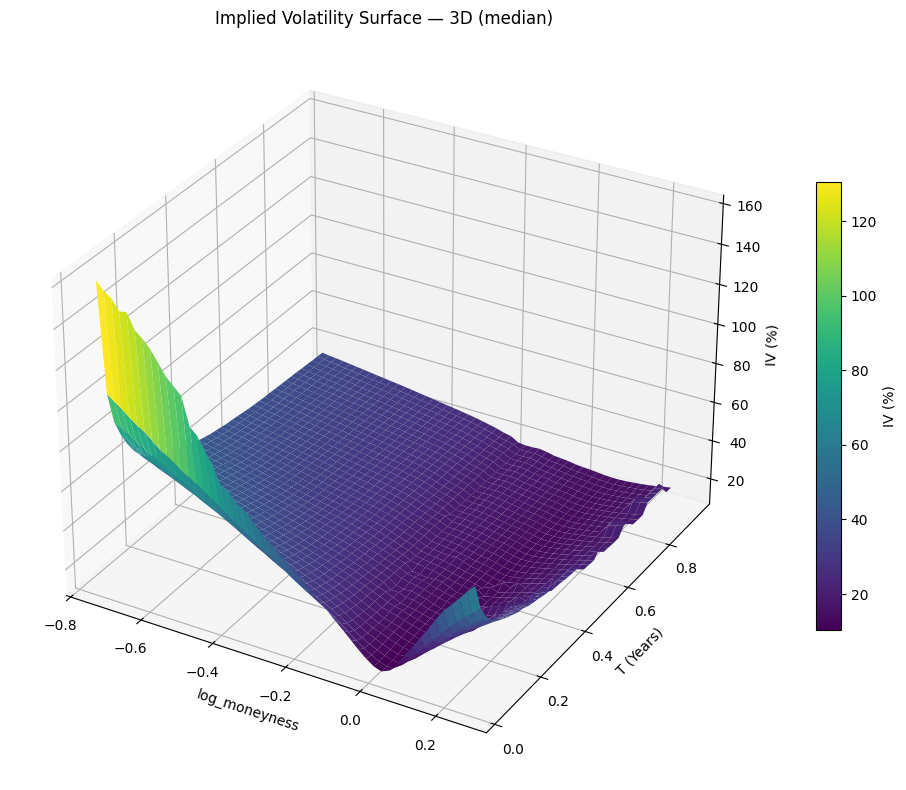

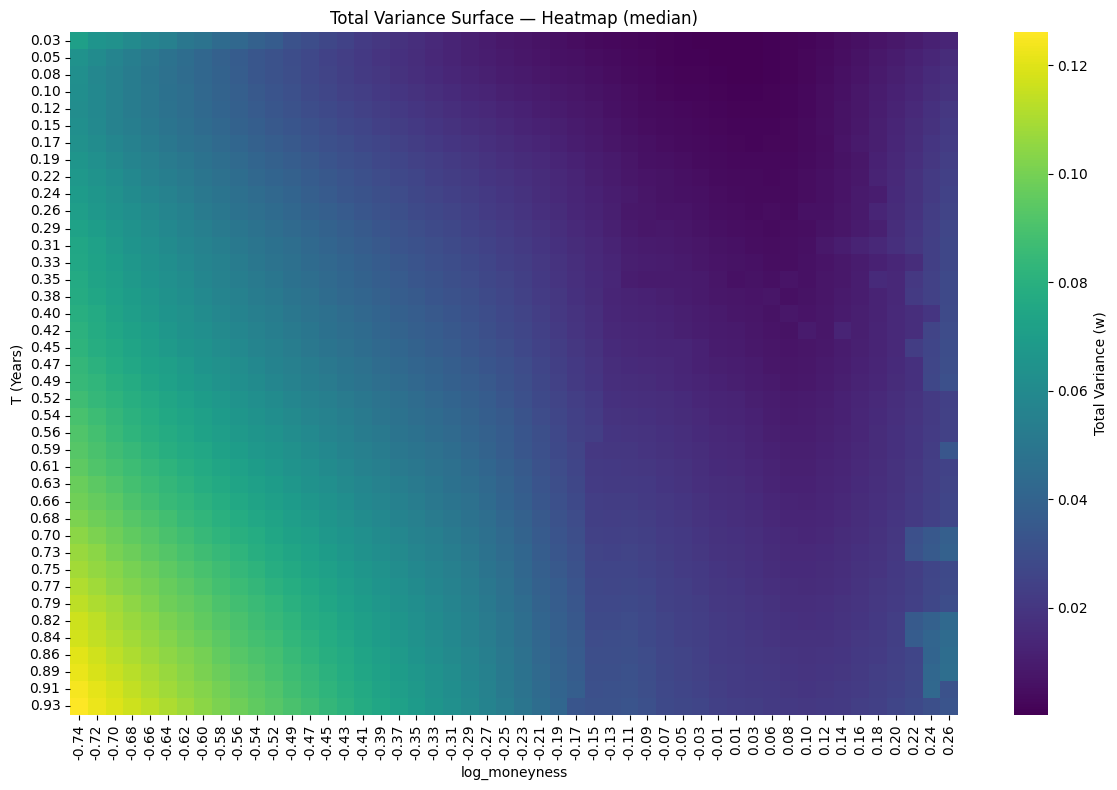

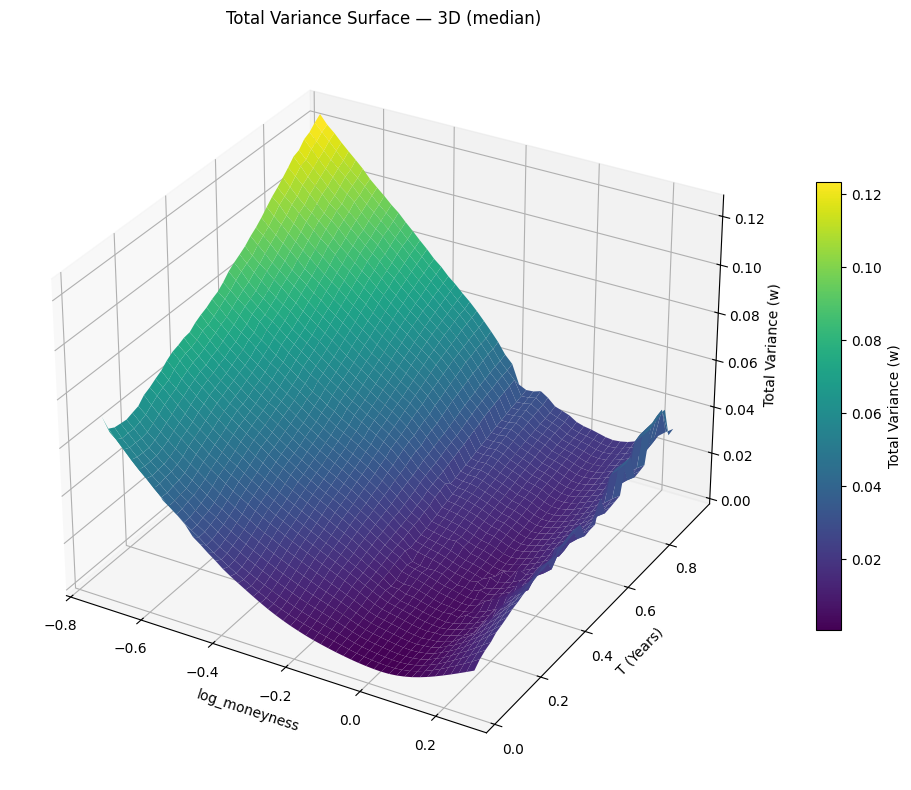

In [16]:
# 1) Superfície teórica
print("IVS Teórica:")
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="iv_teorica",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="Teórica"
)

# 2) Superfície de volatilidade implícita do modelo (não calibrada)
print("IVS Modelo (não calibrada):")
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="Híbrido_XGBoost"
)

# 3) Superfície de volatilidade implícita do modelo (calibrada)
print("IVS Modelo (calibrada):")
plot_ivs_and_variance_surfaces(
    df_test_puro_pred_cal,
    x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="Híbrido_XGBoost_Calibrado"
)